# Week 1 – Superstore Sales Analysis
source:
https://raw.githubusercontent.com/curran/data/gh-pages/superstoreSales/superstoreSales.csv

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('data/superstore_sales_raw.csv', encoding='latin1')  # file is not UTF-8
print(df.shape)
df.head()

(8399, 21)


,Row ID,Order ID,Order Date,Order Priority,Order Quantity,Sales,Discount,Ship Mode,Profit,Unit Price,...,Customer Name,Province,Region,Customer Segment,Product Category,Product Sub-Category,Product Name,Product Container,Product Base Margin,Ship Date
0,1,3,10/13/2010,Low,6,261.5400,0.04,Regular Air,-213.25,38.94,...,Muhammed MacIntyre,Nunavut,Nunavut,Small Business,Office Supplies,Storage & Organization,"Eldon Base for stackable storage shelf, platinum",Large Box,0.80,10/20/2010
1,49,293,10/1/2012,High,49,10123.0200,0.07,Delivery Truck,457.81,208.16,...,Barry French,Nunavut,Nunavut,Consumer,Office Supplies,Appliances,"1.7 Cubic Foot Compact ""Cube"" Office Refrigera...",Jumbo Drum,0.58,10/2/2012
2,50,293,10/1/2012,High,27,244.5700,0.01,Regular Air,46.71,8.69,...,Barry French,Nunavut,Nunavut,Consumer,Office Supplies,Binders and Binder Accessories,"Cardinal Slant-D¨ Ring Binder, Heavy Gauge Vinyl",Small Box,0.39,10/3/2012
3,80,483,7/10/2011,High,30,4965.7595,0.08,Regular Air,1198.97,195.99,...,Clay Rozendal,Nunavut,Nunavut,Corporate,Technology,Telephones and Communication,R380,Small Box,0.58,7/12/2011
4,85,515,8/28/2010,Not Specified,19,394.2700,0.08,Regular Air,30.94,21.78,...,Carlos Soltero,Nunavut,Nunavut,Consumer,Office Supplies,Appliances,Holmes HEPA Air Purifier,Medium Box,0.50,8/30/2010


## Data Cleaning

In [2]:
print('Missing values per column:')
print(df.isna().sum()[df.isna().sum() > 0])
print('Duplicate rows:', df.drop(columns='Row ID').duplicated().sum())
print(df.dtypes)

Missing values per column:
Product Base Margin    63
dtype: int64
Duplicate rows: 0
Row ID                    int64
Order ID                  int64
Order Date                  str
Order Priority              str
Order Quantity            int64
Sales                   float64
Discount                float64
Ship Mode                   str
Profit                  float64
Unit Price              float64
Shipping Cost           float64
Customer Name               str
Province                    str
Region                      str
Customer Segment            str
Product Category            str
Product Sub-Category        str
Product Name                str
Product Container           str
Product Base Margin     float64
Ship Date                   str
dtype: object


In [3]:
df.columns = ['RowID', 'OrderID', 'OrderDate', 'OrderPriority', 'Quantity', 'Sales', 'Discount', 'ShipMode',
              'Profit', 'UnitPrice', 'ShippingCost', 'CustomerName', 'Province', 'Region', 'Segment',
              'Category', 'SubCategory', 'ProductName', 'Container', 'BaseMargin', 'ShipDate']

df = df.drop_duplicates()
text_cols = df.select_dtypes(exclude='number').columns
df[text_cols] = df[text_cols].apply(lambda s: s.str.strip())
df['Region'] = df['Region'].replace({'Prarie': 'Prairie'})
df['OrderDate'] = pd.to_datetime(df['OrderDate'], format='%m/%d/%Y')
df['ShipDate'] = pd.to_datetime(df['ShipDate'], format='%m/%d/%Y')

df['BaseMargin'] = df['BaseMargin'].fillna(df.groupby('SubCategory')['BaseMargin'].transform('median'))

df['ShipDays'] = (df['ShipDate'] - df['OrderDate']).dt.days
assert (df['ShipDays'] >= 0).all(), 'ship date before order date'
assert (df['Quantity'] > 0).all() and (df['Sales'] > 0).all()
assert df['Discount'].between(0, 1).all()

# Outliers (IQR on Sales): flagged, not removed - large orders are real business
q1, q3 = df['Sales'].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
df['IsOutlier'] = df['Sales'] > upper
print('Sales outlier threshold:', round(upper, 2), '| outlier rows:', df['IsOutlier'].sum())

df['Year'] = df['OrderDate'].dt.year
df['Month'] = df['OrderDate'].dt.strftime('%Y-%m')
df.to_csv('data/cleaned_sales.csv', index=False)
print('Cleaned shape:', df.shape, '| nulls left:', df.isna().sum().sum())

Sales outlier threshold: 4058.51 | outlier rows: 1042
Cleaned shape: (8399, 25) | nulls left: 0


## KPIs

In [4]:
kpis = {
    'Total Sales': df['Sales'].sum(),
    'Total Profit': df['Profit'].sum(),
    'Profit Margin %': df['Profit'].sum() / df['Sales'].sum() * 100,
    'Orders': df['OrderID'].nunique(),
    'Units Sold': df['Quantity'].sum(),
    'Avg Order Value': df['Sales'].sum() / df['OrderID'].nunique(),
    'Customers': df['CustomerName'].nunique(),
}
for k, v in kpis.items():
    print(f'{k:16}: {v:,.2f}')

Total Sales     : 14,915,600.82
Total Profit    : 1,521,767.98
Profit Margin % : 10.20
Orders          : 5,496.00
Units Sold      : 214,777.00
Avg Order Value : 2,713.90
Customers       : 795.00


## EDA – Breakdowns & Trend

In [5]:
def summary(col):
    t = df.groupby(col)[['Sales', 'Profit']].sum()
    t['Margin %'] = t['Profit'] / t['Sales'] * 100
    return t.sort_values('Sales', ascending=False).round(1)

print(summary('Year').sort_index().to_string(), end='\n\n')
for col in ['Category', 'Region', 'Segment', 'ShipMode']:
    print(summary(col).to_string(), end='\n\n')
print('Top 5 sub-categories by sales:')
print(summary('SubCategory').head(5).to_string())
print('Bottom 5 sub-categories by profit:')
print(summary('SubCategory').sort_values('Profit').head(5).to_string())

          Sales    Profit  Margin %
Year                               
2009  4209139.5  434538.7      10.3
2010  3549680.8  363871.5      10.3
2011  3436816.7  381456.0      11.1
2012  3719963.9  341901.8       9.2

                     Sales    Profit  Margin %
Category                                      
Technology       5984248.2  886313.5      14.8
Furniture        5178590.5  117433.0       2.3
Office Supplies  3752762.1  518021.4      13.8

                           Sales    Profit  Margin %
Region                                              
West                   3597549.3  297008.6       8.3
Ontario                3063212.5  346868.5      11.3
Prairie                2837304.6  321160.1      11.3
Atlantic               2014248.2  238960.7      11.9
Quebec                 1510195.1  140426.6       9.3
Yukon                   975867.4   73849.2       7.6
Northwest Territories   800847.3  100653.1      12.6
Nunavut                 116376.5    2841.1       2.4

                

## Statistics

In [6]:
s = df['Sales']
print('Sales per line - Mean:', round(s.mean(), 2), '| Median:', s.median(), '| Mode:', s.mode()[0])
print('Std Dev:', round(s.std(), 2))
print('Correlation matrix:')
print(df[['Quantity', 'UnitPrice', 'Discount', 'ShippingCost', 'Sales', 'Profit']].corr().round(2))

print('P(line is Technology):', round((df['Category'] == 'Technology').mean(), 3))
print('P(line makes a loss):', round((df['Profit'] < 0).mean(), 3))

# Simple linear regression: Profit ~ Sales
slope, intercept = np.polyfit(df['Sales'], df['Profit'], 1)
r2 = np.corrcoef(df['Sales'], df['Profit'])[0, 1] ** 2
print(f'Regression: Profit = {slope:.3f} * Sales + {intercept:.2f}  (R2 = {r2:.2f})')

Sales per line - Mean: 1775.88 | Median: 449.42 | Mode: 10.48
Std Dev: 3585.05
Correlation matrix:
              Quantity  UnitPrice  Discount  ShippingCost  Sales  Profit
Quantity          1.00      -0.10     -0.01         -0.01   0.22    0.19
UnitPrice        -0.10       1.00      0.00          0.24   0.60   -0.01
Discount         -0.01       0.00      1.00         -0.00  -0.02   -0.04
ShippingCost     -0.01       0.24     -0.00          1.00   0.43   -0.02
Sales             0.22       0.60     -0.02          0.43   1.00    0.58
Profit            0.19      -0.01     -0.04         -0.02   0.58    1.00
P(line is Technology): 0.246
P(line makes a loss): 0.508
Regression: Profit = 0.194 * Sales + -163.78  (R2 = 0.34)


## Visualizations

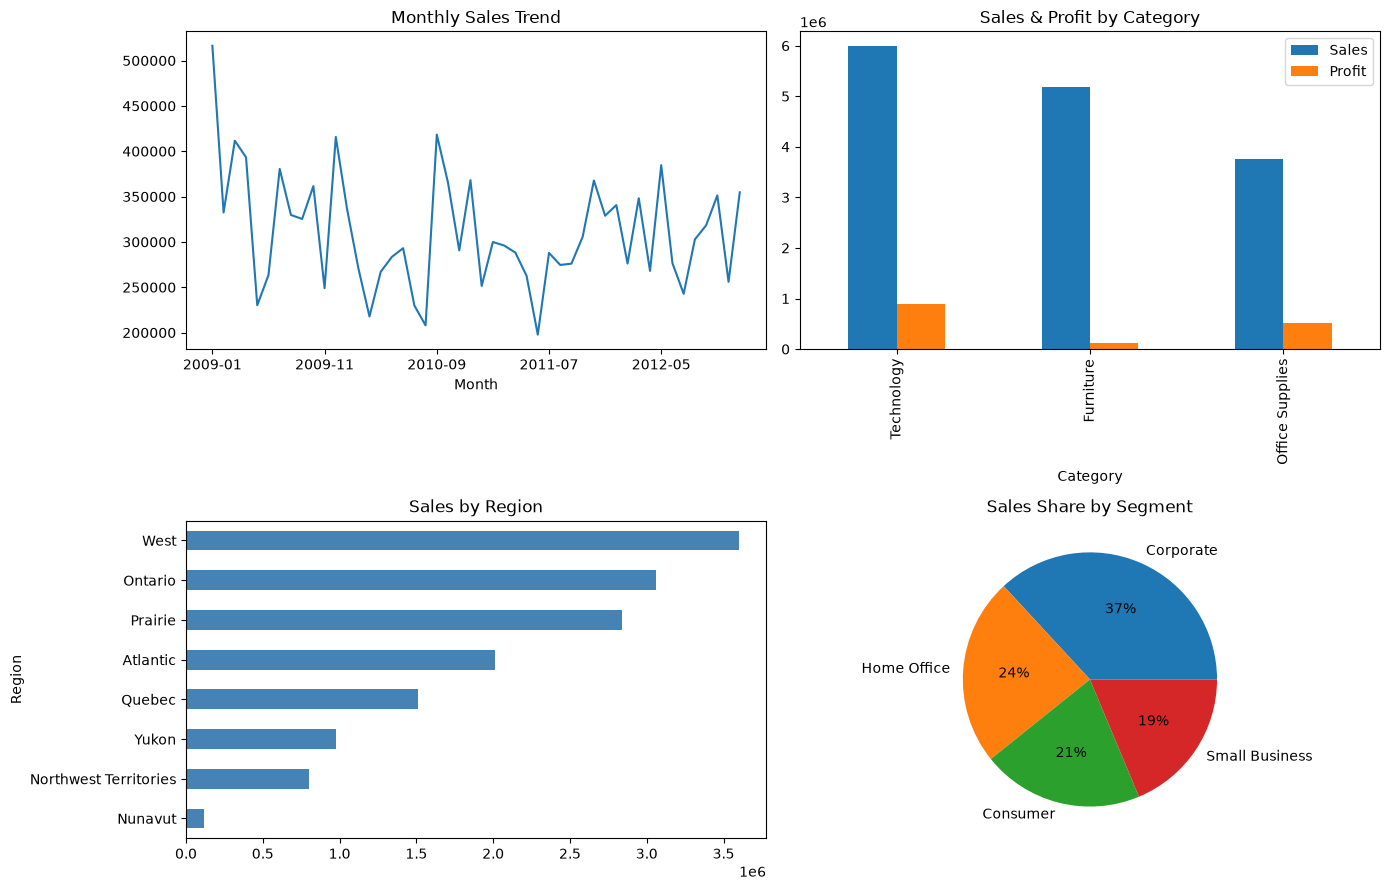

In [7]:
monthly = df.groupby('Month')['Sales'].sum()
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
monthly.plot(ax=ax[0, 0], title='Monthly Sales Trend')
summary('Category')[['Sales', 'Profit']].plot.bar(ax=ax[0, 1], title='Sales & Profit by Category')
summary('Region')['Sales'].sort_values().plot.barh(ax=ax[1, 0], title='Sales by Region', color='steelblue')
summary('Segment')['Sales'].plot.pie(ax=ax[1, 1], autopct='%1.0f%%', title='Sales Share by Segment', ylabel='')
plt.tight_layout()
plt.show()

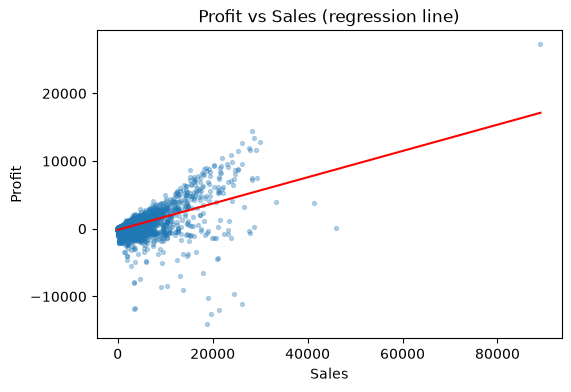

In [8]:
plt.figure(figsize=(6, 4))
plt.scatter(df['Sales'], df['Profit'], alpha=0.3, s=8)
x = np.linspace(0, df['Sales'].max(), 50)
plt.plot(x, slope * x + intercept, color='red')
plt.title('Profit vs Sales (regression line)')
plt.xlabel('Sales')
plt.ylabel('Profit')
plt.show()